**Avant de débuter ce TP** :

1. **Changez le type d'exécution sur Google Colab** : `Exécution > Modifiez le type d'exécution > T4 GPU`
2. **Installez les paquets ci-dessous** :

In [1]:
! pip install aeon lightning torchmetrics torchinfo

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 52.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 32.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 29.8 MB/s eta 0:00:00


3. Exécutez ce code pour supprimer quelques messages et avertissements éventuellement affichés.

In [2]:
import logging
logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.accelerators.cuda").setLevel(logging.WARNING)
logger = logging.getLogger("lightning")
logger.propagate = False

import warnings
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*Missing logger folder.*")
warnings.filterwarnings("ignore", "`isinstance\\(treespec, LeafSpec\\)` is deprecated.*")

# Identification de chiffres arabiques prononcés

Dans ce notebook, vous allez travailler sur le jeu de données [Spoken Arabic Digits](https://timeseriesclassification.com/description.php?Dataset=SpokenArabicDigits).

Ce jeu de données a été construit à partir d'enregistrements de 44 hommes et 44 femmes arabophones âgés de 18 à 40 ans prononçant les dix chiffres arabes.
Voici quelques informations supplémentaires sur les expériences effectuées :

> This data set is taken from the UCI repository. It is derived from sound. Dataset from 8800 (10 digits x 10 repetitions x 88 speakers) time series of 13 Frequency Cepstral Coefficients (MFCCs) had taken from 44 males and 44 females Arabic native speakers between the ages 18 and 40 to represent ten spoken Arabic digit. Each line on the data base represents 13 MFCCs coefficients in the increasing order separated by spaces. This corresponds to one analysis frame. The 13 Mel Frequency Cepstral Coefficients (MFCCs) are computed with the following conditions; Sampling rate: 11025 Hz, 16 bits Window applied: hamming Filter pre-emphasized: 1-0.97Z^(-1).

**L'objectif est de prédire le chiffre prononcé par le sujet à partir des signaux audio enregistrés puis prétraités.**

## Téléchargement des données, visualisation et prétraitement

La cellule ci-dessous permet de télécharger et charger le jeu de données.

In [3]:
from aeon.datasets import load_classification

X, y = load_classification(
    "SpokenArabicDigits", split=None, load_equal_length=True, extract_path="data"
)

Deux variables Python sont définies :

* `X` contient les entrées (c'est-à-dire les signaux) ; il s'agit d'un tableau NumPy de taille `(n_observations, n_canaux, n_points)`.
* `y` contient les sorties (c'est-à-dire les classes) ; il s'agit d'un tableau NumPy de taille `(n_observations,)`.

### Question 1

**(a)** Déterminez les nombres d'observations (`n_observations`), de canaux (`n_canaux`) et de points (`n_points`).

**(b)** Déterminez les valeurs des classes, c'est-à-dire les valeurs uniques du tableau NumPy `y`.

In [11]:
# question 1 a
n_observations, n_canaux, n_points = X.shape
print(f"Nombre d'observations : {n_observations}")
print(f"Nombre de canaux : {n_canaux}")
print(f"Nombre de points : {n_points}")

Nombre d'observations : 8798
Nombre de canaux : 13
Nombre de points : 65


In [12]:
# question 1 b
import numpy as np
print(f"Classes : {np.unique(y)}")

Classes : ['1' '10' '2' '3' '4' '5' '6' '7' '8' '9']


### Question 2

Effectuez les transformations nécessaires sur les variables `X` et `y` pour les mettre aux formats adaptés. On vous rappelle que :

* les entrées doivent être des nombres flottants à 32 bits.
* les classes doivent être des nombres entiers à  64 bits et que les valeurs des classes doivent être les $C$ premiers entiers naturels (en commençant à compter à partir de zéro), où $C$ est le nombre de classes.

Pour ce faire, vous pouvez utiliser la méthode [`numpy.ndarray.astype()`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.astype.html) ou la fonction [`numpy.astype()`](https://numpy.org/doc/2.0/reference/generated/numpy.astype.html). Les types correspondants sont `numpy.float32` et `numpy.int64` respectivement.

In [14]:
# Question 2, on change les formats
import numpy as np

X = X.astype(np.float32)
y = y.astype(np.int64) - 1



La fonction `plot_sample()` définie ci-dessous permet d'afficher une observation.

In [15]:
import matplotlib.pyplot as plt


def plot_sample(X, y, idx):
    """Plot the sample for the given index.

    Parameters
    ----------
    X : array, shape = (n_samples, n_channels, n_points)
        Input samples.

    y : array, shape = (n_samples)
        Target samples.

    idx : int
        Index of the sample to plot.
    """
    if not (isinstance(idx, int) and (0 <= idx < len(X))):
        raise ValueError("L'indice n'est pas valide.")

    for i in range(X.shape[1]):
        plt.plot(X[idx, i])
    _ = plt.title(f"Chiffre {y[idx].item()}")

### Question 3

Appelez la fonction `plot_sample()` pour visualiser quelques observations du jeu de données.

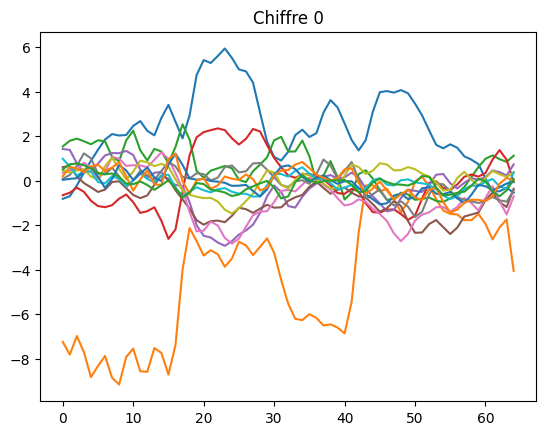

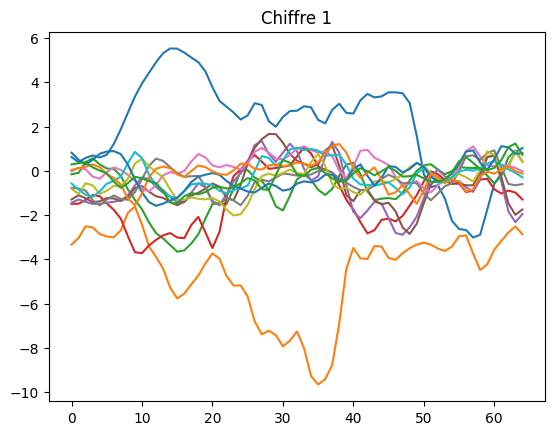

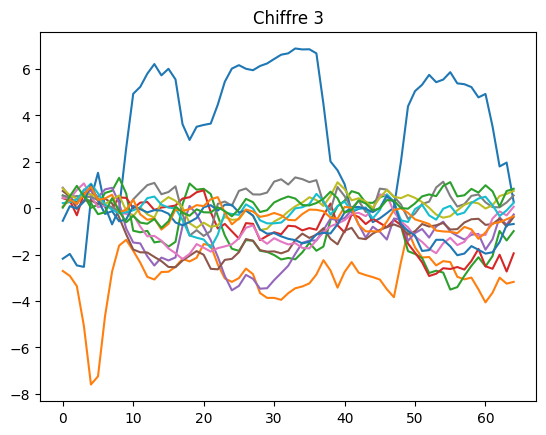

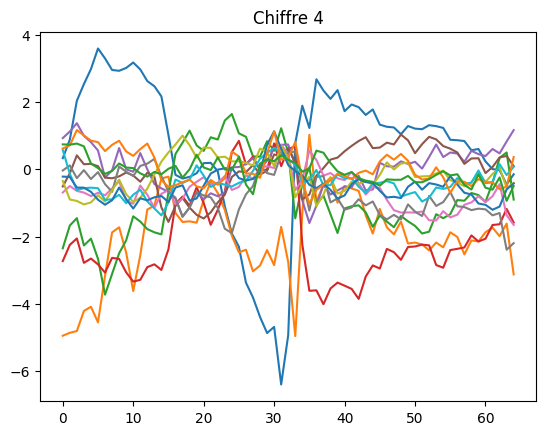

In [23]:
# question 3 j'affiche 4 observations assez différentes 0, 1000, 2000, 3000
import matplotlib.pyplot as plt
for idx in [0, 1000, 2000, 3000]:
    plot_sample(X, y, idx)
    plt.show()


### Question 4

Calculez la distribution des classes.
Utilisez ces résultats pour proposer une métrique de classification pertinente.
Pour cette métrique, indiquez la valeur (approximative) d'un modèle trivial, par exemple celui prédisant toujours la même classe ou celui prédisant les classes de manière totalement aléatoire (sans utiliser les données en entrée).

In [25]:
# question 4 étudions la distribution des classes , elles sont équilibrés (presque 880 à chaque fois)
import numpy as np

classes, counts = np.unique(y, return_counts=True)

print(f"Effectifs par classe : {counts}")
print(f"Distribution des classes : {counts / counts.sum()}")

Effectifs par classe : [880 880 880 880 880 880 880 880 880 878]
Distribution des classes : [0.10002273 0.10002273 0.10002273 0.10002273 0.10002273 0.10002273
 0.10002273 0.10002273 0.10002273 0.09979541]


Les classes sont équilibrées, on peut utiliser l'accuracy (ou exactitude) comme métrique adaptée. Un modèle trivial qui prédirait toujours la même classe donnerait une exactitude de 1/10 (il y a 10 classes), de même pour un modèle totalement aléatoire.

### Question 5

Séparez le jeu de données en trois jeux de données :

* le jeu d'entraînement avec 6000 observations,
* le jeu de validation avec 1000 observations, et
* le jeu d'évaluation avec le reste.

Pour ce faire, vous pouvez utiliser la fonction [`sklearn.model_selection.train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html). Les trois jeux de données doivent conserver (approximativement) la distribution des classes, vous utiliserez l'argument `stratify` pour respecter cette propriété.

In [30]:
# question 5, on fait xomme au TP, on raisonne en 2 temps, le stratify permet de conserver la distribution des classes
#le X_train_val et y_train_val est juste une étape intermédiaire et le X_test et y_test contiennent le reste
# au final on a les 3 jeux train, val (issu de train_val) et test. Le test est le jeu d'évaluation
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, train_size=7000, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, train_size=6000, stratify=y_train_val
)

del X_train_val, y_train_val

### Question 6

L'approche utilisée à la question précédente a un inconvénient méthodologique. Identifiez lequel. La réponse se trouve dans la description du jeu de données, au début de ce notebook.

> **Remarque** : Ne passez pas trop de temps sur cette question, ce n'est pas très grave si vous n'avez pas la réponse. Vous pourrez également y réfléchir pendant l'entraînement des modèles.

**Réponse** : Je pense que l'inconvénient est que l'on considère toutes les observations comme "indépendantes" alors même qu'elles sont issue de 44 H et 44 F, on devrait donc aussi respecter cette répartition pour éviter d'avoir un échantillon par exemple qui ne contiendrait que les valeurs de certaines personnes ou d'un certain sexe par exemple. Il faudrait construire nos échantillons en respectant ces criteres distinctifs importants pour la classification.

### Question 7

Convertissez vos 6 tableaux NumPy (les entrées et les sorties pour les trois jeux de données) en tenseurs PyTorch. La fonction à utiliser est [`torch.from_numpy()`](https://docs.pytorch.org/docs/2.14/generated/torch.from_numpy.html).

In [31]:
# on convertit en tenseurs PyTorch, ils sont deja du bon type (float32 et int64) donc pas besoin de .to ni du -1 fais à la question 2
import torch

X_train = torch.from_numpy(X_train)
X_val = torch.from_numpy(X_val)
X_test = torch.from_numpy(X_test)

y_train = torch.from_numpy(y_train)
y_val = torch.from_numpy(y_val)
y_test = torch.from_numpy(y_test)

### Question 8

Créez les *dataloaders* pour les jeux d'entraînement et de validation en utilisant la classe [`torch.utils.data.DataLoader()`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) avec des lots de taille $32$. N'oubliez pas de mélanger (*shuffle*) les observations pour le jeu d'entraînement, mais pas pour le jeu de validation. Pour créer les jeux de données, vous pouvez utiliser la classe [`torch.utils.data.TensorDataset()`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.TensorDataset).

In [32]:
# question 8 creation des data loader sur le modele de la question 4 du TP 1.2, en adaptant la taille à 32,
#le shuffle n'intervient que pour le train

from torch.utils.data import DataLoader, TensorDataset


dataloader_train = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
dataloader_val = DataLoader(TensorDataset(X_val, y_val), batch_size=32, shuffle=False)
dataloader_test = DataLoader(TensorDataset(X_test, y_test), batch_size=32, shuffle=False)


## Classe de base pour la classification

Vous allez entraîner plusieurs modèles avec des architectures différentes.
Néanmoins, plusieurs opérations seront identiques pour tous ces modèles.
C'est pourquoi nous allons tout d'abord définir une classe de base avec toutes les opérations identiques.
La classe `BaseClass()` définie ci-dessous va contenir ces opérations communes.

### Question 9

Complétez le code manquant dans les méthodes `__init__()`, `step()` et `configure_optimizers()` de la classe `BaseClass()` avec les informations suivantes :
* `__init__()` : il faut définir la fonction de perte (`self.loss`) et les métriques pour les jeux d'entraînement (`self.metric_train`) et d'évaluation (`self.metric_val`);
* `step()` : étant donné un lot d'observations (`batch`), il faut :
    + récupérer les entrées (`X`) et les labels (`y`),
    + calculer les logits pour ces entrées (`logits`),
    + calculer la fonction de coût entre les logits et les labels (`loss`),
    + calculer la classe prédite pour chacune des observations du lot (`y_pred`).
* `configure_optimizers()` : on utilisera l'algorithme d'optimisation [`torch.optim.Adam()`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html) avec un taux d'apprentissage (*learning rate*) de $10^{-4}$.

In [33]:
import lightning as L
# il manque le torchmetrics. Accuracy
from torchmetrics import Accuracy


class BaseClass(L.LightningModule):

    def __init__(self):
        """Constructeur.

        Dans le constructeur, on exécute le constructeur de la clase mère et on définit
        toutes les couches et fonctions d'activation de notre réseau de neurones.
        """
        super().__init__()  # Toujours exécuter le constructeur de la classe mère

        ### BEGIN TODO ###
        # Initialisation de la fonction de perte
        self.loss = torch.nn.CrossEntropyLoss()

        # Initialisation des métriques
        self.metric_train = Accuracy(task="multiclass", num_classes=10)
        self.metric_val = Accuracy(task="multiclass", num_classes=10)
        #### END TODO ####

    def step(self, batch, dataset):
        """Effectue une étape.

        Une étape consiste à passer d'un lot d'observations (l'argument batch)
        à l'évaluation de la fonction de coût pour ce lot d'observations.

        Parameters
        ----------
        batch : tuple
            Un lot d'observations. Le premier élément du tuple est le lot
            des entrées, le second est le lot des labels.

        dataset : {"training", "validation"}
            Jeu de données utilisé.

        Returns
        -------
        loss : Tensor, shape = (1,)
            La fonction de coût pour ce lot d'observations.
        """
        ### BEGIN TODO ###
        X, y =  batch # X correspond aux signaux, y aux classes
        logits = self(X)  # Passe avant, qui renvoie les logits
        loss = self.loss(logits, y)  # Évaluation de la fonction de perte
        y_pred = logits.argmax(1)  # Prédictions du modèle
        #### END TODO ###

        if dataset == "training":
            metric = self.metric_train
            name = "train"
            bar_step = True
        else:
            metric = self.metric_val
            name = "val"
            bar_step = False

        metric_score = metric(y_pred, y) # Évaluation de la métrique
        self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"metric_{name}", metric_score, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Effectue une étape d'entraînement."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Effectue une étape de validation."""
        return self.step(batch, "validation")

    def on_train_start(self):
        """Code exécuté au début de l'entraînement."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code exécuté à la fin de chaque époque d'entraînement."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Époque {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -------------------------------------------------
            |     Jeu      | Fonction de perte | Exactitude |
            | ------------ | ----------------- | ---------- |
            | Entraînement |{metrics['loss_train'].item():^19.5f}|{metrics['metric_train'].item():^12.3%}|
            |  Validation  |{metrics['loss_val'].item():^19.5f}|{metrics['metric_val'].item():^12.3%}|
            -------------------------------------------------
        """)
        string = '\n'.join([line.strip() for line in string.strip().split('\n')])
        print(string, '\n')

    def configure_optimizers(self):
        """Configure l'algorithme d'optimisation à utiliser."""
        ### BEGIN TODO ###
        optimizer = torch.optim.Adam(self.parameters())
        #### END TODO ####
        return optimizer

## Classification par perceptron multicouche

Comme la longueur de chacun des signaux est fixe après prétraitement des données, il est possible d'utiliser un perceptron multicouche.

Vous allez implémenter un perceptron multicouche dans la classe `MLP()` définie ci-dessous avec l'architecture séquentielle suivante :

* Aplatissement de l'observation pour la transformer en un tenseur à une dimension (un vecteur)
* Couche linéaire avec 256 variables en sortie
* Fonction d'action ReLU
* Couche de désaction (*dropout*) avec une probabilité de $0.2$
* Couche linéaire avec 64 variables en sortie
* Fonction d'action ReLU
* Couche linéaire avec 10 variables en sortie

Voici les liens vers les documentations des classes pertinentes :
[`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html),
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html),
[`torch.nn.ReLU()`](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html) et
[`torch.nn.Dropout()`](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html).

### Question 10

Complétez le code manquant dans les méthodes `__init__()` et `forward()` de la classe `MLP()`.
Affichez un résumé de l'architecture. Combien de paramètres entraînables a-t-elle ?

In [35]:
class MLP(BaseClass):

    def __init__(self):
        super().__init__()

        ### BEGIN TODO ###

        # Initialisation de la séquence de couches et de fonctions d'activation il y a 13 canaux et 65 points
        self.sequential = torch.nn.Sequential(
            torch.nn.Flatten(),
            torch.nn.Linear(13*65, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2, inplace=False),
            torch.nn.Linear(256, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, 10),
        )

        #### END TODO ####

    def forward(self, x):
        ### BEGIN TODO ###
        logits = self.sequential(x)
        #### END TODO ####
        return logits

In [36]:
from torchinfo import summary

model = MLP()
summary(model, input_size=(32, 13, 65))

Layer (type:depth-idx)                   Output Shape              Param #
MLP                                      [32, 10]                  --
├─Sequential: 1-1                        [32, 10]                  --
│    └─Flatten: 2-1                      [32, 845]                 --
│    └─Linear: 2-2                       [32, 256]                 216,576
│    └─ReLU: 2-3                         [32, 256]                 --
│    └─Dropout: 2-4                      [32, 256]                 --
│    └─Linear: 2-5                       [32, 64]                  16,448
│    └─ReLU: 2-6                         [32, 64]                  --
│    └─Linear: 2-7                       [32, 10]                  650
Total params: 233,674
Trainable params: 233,674
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 7.48
Input size (MB): 0.11
Forward/backward pass size (MB): 0.08
Params size (MB): 0.93
Estimated Total Size (MB): 1.13

D'apres le résumé il y a donc 233 674 paramètres entrainables.

### Question 11

Entraînez votre modèle pendant $10$ époques.

In [37]:
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model = MLP()

trainer = L.Trainer(
    max_epochs=10,
    enable_model_summary=False,  # supprimer le résumé du modèle
    logger=CSVLogger('.'),  # sauvegarder les résultats dans un fichier CSV
    num_sanity_val_steps=0,  # ne pas effectuer d'étape de validation avant l'entraînement
    callbacks=[TQDMProgressBar(refresh_rate=100)]  # mettre à jour la barre de progression tous les 100 lots
)

trainer.fit(
    model=model,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

Training: |          | 0/? [00:00<?, ?it/s]

Version 0



Validation: |          | 0/? [00:00<?, ?it/s]

Époque 1 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      0.30394      |  91.067%   |
|  Validation  |      0.09240      |  97.200%   |
------------------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

...

Époque 8 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      0.00673      |  99.800%   |
|  Validation  |      0.02996      |  99.300%   |
------------------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Époque 9 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      0.01077      |  99.667%   |
|  Validation  |      0.07075      |  98.000%   |
------------------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Époque 10 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      0.02170      |  99.200%   |
|  Validation  |      0.06792      |  98.400%   |
------------------------------------------------- 



## Classification par réseau de neurones convolutif

Comme la longueur de chacun des signaux est fixe après prétraitement des données et que les données sont séquentielles, il est également possible et pertinent d'utiliser un réseau de neurones convolutif.

Vous allez implémenter un réseau de neurones convolutif dans la classe `CNN()` définie ci-dessous avec l'architecture séquentielle suivante :

* Couche de convolution unidimensionnelle avec $32$ canaux en sortie et un noyau de taille $7$
* Fonction d'action ReLU
* Couche de regroupement unidimensionnelle avec un noyau et un pas de taille $2$
* Couche de convolution unidimensionnelle avec $64$ canaux en sortie et un noyau de taille $5$
* Fonction d'action ReLU
* Couche de regroupement unidimensionnelle avec un noyau et un pas de taille $2$
* Couche de convolution unidimensionnelle avec $128$ canaux en sortie et un noyau de taille $3$
* Fonction d'action ReLU
* Couche de regroupement unidimensionnelle avec un noyau et un pas de taille $2$
* Aplatissement de l'entrée (en deux dimensions) pour la transformer en un tenseur à une dimension (un vecteur)
* Couche linéaire avec $640$ variables en entrée et $256$ variables en sortie
* Fonction d'action ReLU
* Couche linéaire avec $10$ variables en sortie

Voici les liens vers les documentations des classes pertinentes :
[`torch.nn.Conv1d()`](https://pytorch.org/docs/stable/generated/torch.nn.Conv1d.html),
[`torch.nn.ReLU()`](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html),
[`torch.nn.MaxPool1d()`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool1d.html),
[`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html) et
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html).

### Question 12

Complétez le code manquant dans les méthodes `__init__()` et `forward()` de la classe `CNN()`.
Affichez un résumé de l'architecture. Combien de paramètres entraînables a-t-elle ?

In [39]:
class CNN(BaseClass):

    def __init__(self):
        super().__init__()

        ### BEGIN TODO ###
        ### couche CV1 ###
        self.cv1 = torch.nn.Conv1d(in_channels=13, out_channels=32, kernel_size=7)
        self.relu1 = torch.nn.ReLU()
        self.pool1 = torch.nn.MaxPool1d(kernel_size=2, stride=2)
        ### couche CV2 ###
        self.cv2 = torch.nn.Conv1d(in_channels=32, out_channels=64, kernel_size=5)
        self.relu2 = torch.nn.ReLU()
        self.pool2 = torch.nn.MaxPool1d(kernel_size=2, stride=2)
        ### couche CV3 ###
        self.cv3 = torch.nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3)
        self.relu3 = torch.nn.ReLU()
        self.pool3 = torch.nn.MaxPool1d(kernel_size=2, stride=2)
        ### applatissement ###
        self.flatten = torch.nn.Flatten()
        ### fc lineaire ###
        self.fc1 = torch.nn.Linear(640, 256)
        self.relu4 = torch.nn.ReLU()
        ### fc lineaire2 ###
        self.fc2 = torch.nn.Linear(256, 10)
        #### END TODO ####

    def forward(self, x):
        ### BEGIN TODO ###
        y = self.pool1(self.relu1(self.cv1(x)))
        y = self.pool2(self.relu2(self.cv2(y)))
        y = self.pool3(self.relu3(self.cv3(y)))
        y = self.flatten(y)
        y = self.relu4(self.fc1(y))
        logits = self.fc2(y)
        #### END TODO ####
        return logits


In [40]:
# TODO
model = CNN()
summary(model, input_size=(32, 13, 65))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [32, 10]                  --
├─Conv1d: 1-1                            [32, 32, 59]              2,944
├─ReLU: 1-2                              [32, 32, 59]              --
├─MaxPool1d: 1-3                         [32, 32, 29]              --
├─Conv1d: 1-4                            [32, 64, 25]              10,304
├─ReLU: 1-5                              [32, 64, 25]              --
├─MaxPool1d: 1-6                         [32, 64, 12]              --
├─Conv1d: 1-7                            [32, 128, 10]             24,704
├─ReLU: 1-8                              [32, 128, 10]             --
├─MaxPool1d: 1-9                         [32, 128, 5]              --
├─Flatten: 1-10                          [32, 640]                 --
├─Linear: 1-11                           [32, 256]                 164,096
├─ReLU: 1-12                             [32, 256]                 --

d'apres le summary il y a 204618 paramètres entrainables

### Question 13

Entraînez votre modèle pendant $10$ époques.

In [45]:
# entrainement sur 10 périodes  on change juste le modele
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model_cnn = CNN()

trainer_cnn = L.Trainer(
    max_epochs=10,
    enable_model_summary=False,  # supprimer le résumé du modèle
    logger=CSVLogger('.'),  # sauvegarder les résultats dans un fichier CSV
    num_sanity_val_steps=0,  # ne pas effectuer d'étape de validation avant l'entraînement
    callbacks=[TQDMProgressBar(refresh_rate=100)]  # mettre à jour la barre de progression tous les 100 lots
)

trainer_cnn.fit(
    model=model_cnn,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)



Training: |          | 0/? [00:00<?, ?it/s]

Version 2



Validation: |          | 0/? [00:00<?, ?it/s]

Époque 1 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      0.41860      |  86.150%   |
|  Validation  |      0.17977      |  94.400%   |
------------------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

...

Époque 8 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      0.01538      |  99.533%   |
|  Validation  |      0.07020      |  98.500%   |
------------------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Époque 9 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      0.01626      |  99.500%   |
|  Validation  |      0.07115      |  97.600%   |
------------------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Époque 10 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      0.01929      |  99.317%   |
|  Validation  |      0.04399      |  99.100%   |
------------------------------------------------- 



## Classification par réseau de neurones récurrent

Comme les données sont séquentielles, il est également possible et pertinent d'utiliser un réseau de neurones récurrent.

Vous allez implémenter un réseau de neurones récurrent dans la classe `RNN()` définie ci-dessous avec l'architecture séquentielle suivante :

* Couche récurrente de type LSTM (unidirectionnelle) avec $256$ variables pour chaque état caché
* Couche linéaire avec 10 variables en sortie

Voici les liens vers les documentations des classes pertinentes :
[`torch.nn.LSTM()`](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html) et
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html).
Lisez attentativement la documentation de la classe [`torch.nn.LSTM()`](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html), notamment concernant les formes attendues des tenseurs en entrée et en sortie.
Vous pouvez utiliser la fonction [`torch.transpose()`](https://docs.pytorch.org/docs/2.14/generated/torch.transpose.html) pour modifier l'ordre des dimensions d'un tenseur.

### Question 14

Complétez le code manquant dans les méthodes `__init__()` et `forward()` de la classe `RNN()`.
Affichez un résumé de l'architecture. Combien de paramètres entraînables a-t-elle ?

In [43]:
class RNN(BaseClass):

    def __init__(self):
        super().__init__()

        ### BEGIN TODO ###
        self.lstm = torch.nn.LSTM(input_size=13, hidden_size=256, batch_first=True)
        self.linear = torch.nn.Linear(256, 10)
        #### END TODO ####

    def forward(self, x):
        ### BEGIN TODO ###
        x = torch.transpose(x, 1, 2)    # (lot, 13, 65) -> (lot, 65, 13)
        _, (h_n, _) = self.lstm(x)      # h_n : (1, lot, 256)
        logits = self.linear(h_n[-1])   # h_n[-1] : (lot, 256)
        #### END TODO ####
        return logits


In [44]:
model = RNN()
summary(model, input_size=(32, 13, 65))

Layer (type:depth-idx)                   Output Shape              Param #
RNN                                      [32, 10]                  --
├─LSTM: 1-1                              [32, 65, 256]             277,504
├─Linear: 1-2                            [32, 10]                  2,570
Total params: 280,074
Trainable params: 280,074
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 577.29
Input size (MB): 0.11
Forward/backward pass size (MB): 4.26
Params size (MB): 1.12
Estimated Total Size (MB): 5.49

Avec le modele de réseaux de neuronnes récurrents, il y a 280074 paramètres entrainables, ils sont donc assez proches les uns des autres

### Question 15

Entraînez votre modèle pendant $10$ époques.

In [46]:
# entrainement sur 10 périodes  on change juste le modele
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model_rnn = RNN()

trainer_rnn = L.Trainer(
    max_epochs=10,
    enable_model_summary=False,  # supprimer le résumé du modèle
    logger=CSVLogger('.'),  # sauvegarder les résultats dans un fichier CSV
    num_sanity_val_steps=0,  # ne pas effectuer d'étape de validation avant l'entraînement
    callbacks=[TQDMProgressBar(refresh_rate=100)]  # mettre à jour la barre de progression tous les 100 lots
)

trainer_rnn.fit(
    model=model_rnn,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)


Training: |          | 0/? [00:00<?, ?it/s]

Version 3



Validation: |          | 0/? [00:00<?, ?it/s]

Époque 1 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      1.15906      |  58.467%   |
|  Validation  |      0.65386      |  79.400%   |
------------------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

...

Époque 8 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      0.04976      |  98.517%   |
|  Validation  |      0.07947      |  97.700%   |
------------------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Époque 9 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      0.05133      |  98.317%   |
|  Validation  |      0.10976      |  96.700%   |
------------------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Époque 10 / 10
-------------------------------------------------
|     Jeu      | Fonction de perte | Exactitude |
| ------------ | ----------------- | ---------- |
| Entraînement |      0.03538      |  99.017%   |
|  Validation  |      0.04895      |  98.700%   |
------------------------------------------------- 



### Question 16

Finalement, lequel de vos trois modèles est le meilleur ? Justifiez votre réponse.

**Réponse** : Si on compare les 3 modèles, le plus efficace est le secod, le reseau de neuronne convolutif, avec plus de 99% d'efficacité sur le test, et 204618 paramètres entrainables. Donc il est à la fois le plus performant et celui qui utilise le moins de paramètres entrainables (donc le plus efficace). A prendre cependant en compte : on a toujours le soucis des échantillons de train/vam/test qui ne prennent pas en compte le fait que les données sont en fait corrélées (les personnes sont interrogés plusieurs fois et il y a des hommes et des femmes), cela necessiterait surement une autre méthode de choix d'échantillonage pour en tenir compte et valider que la méthode CNN est ici la plus adaptée.